## Imports

In [2]:
import emoatlas
import nltk
from nltk.corpus import stopwords
from emoatlas import EmoScores
import pandas as pd
import spacy
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import Counter
import re
import os

In [3]:
# for english
spacy.load('en_core_web_lg')
emos = EmoScores(language='english')

In [8]:
# for itlian
spacy.load('it_core_news_lg')
emos = EmoScores(language='italian')

In [39]:
pd.set_option('display.max_rows', 100)
pd.set_option("display.max_colwidth", None)

In [27]:
path = '/Users/emma/projects/cognoscolab/rassereno'

# Data 2024

## Texts reading and grouping by year

In [5]:
# reads the file with the stored texts of the 169 participants recruited in 2024
text_file = pd.read_csv(f"{path}/out/formatting/psychology_BA_2024/text_task_2024.csv")

In [6]:
# keywords that we want to check for in the textual data
keywords = ['matematica', 'fisica', 'psicologia', 'scienza']

years = ['first', 'second', 'third']
# creates a list with the texts of all the different academic years 
all_texts = []

for year in years:
    # gets the data for each sample group based on the year of the participant_id
    year_data = text_file[text_file['participant_id'].str.startswith(year)]
    # joins all the different texts into a big text one
    joined_text = ".".join(year_data['text'])
    # removes the unnecessary sentence of the instruction (case insensitively)
    cleaned_text = re.sub(r'(?i)quando affronto le discipline STEM', '', joined_text)
    # insert the variables containing all the texts for each year into a list 
    all_texts.append(cleaned_text)

## Forma Mentis Networks building

⚠️ Skipping psicologia_first_year: not enough data to build the network.


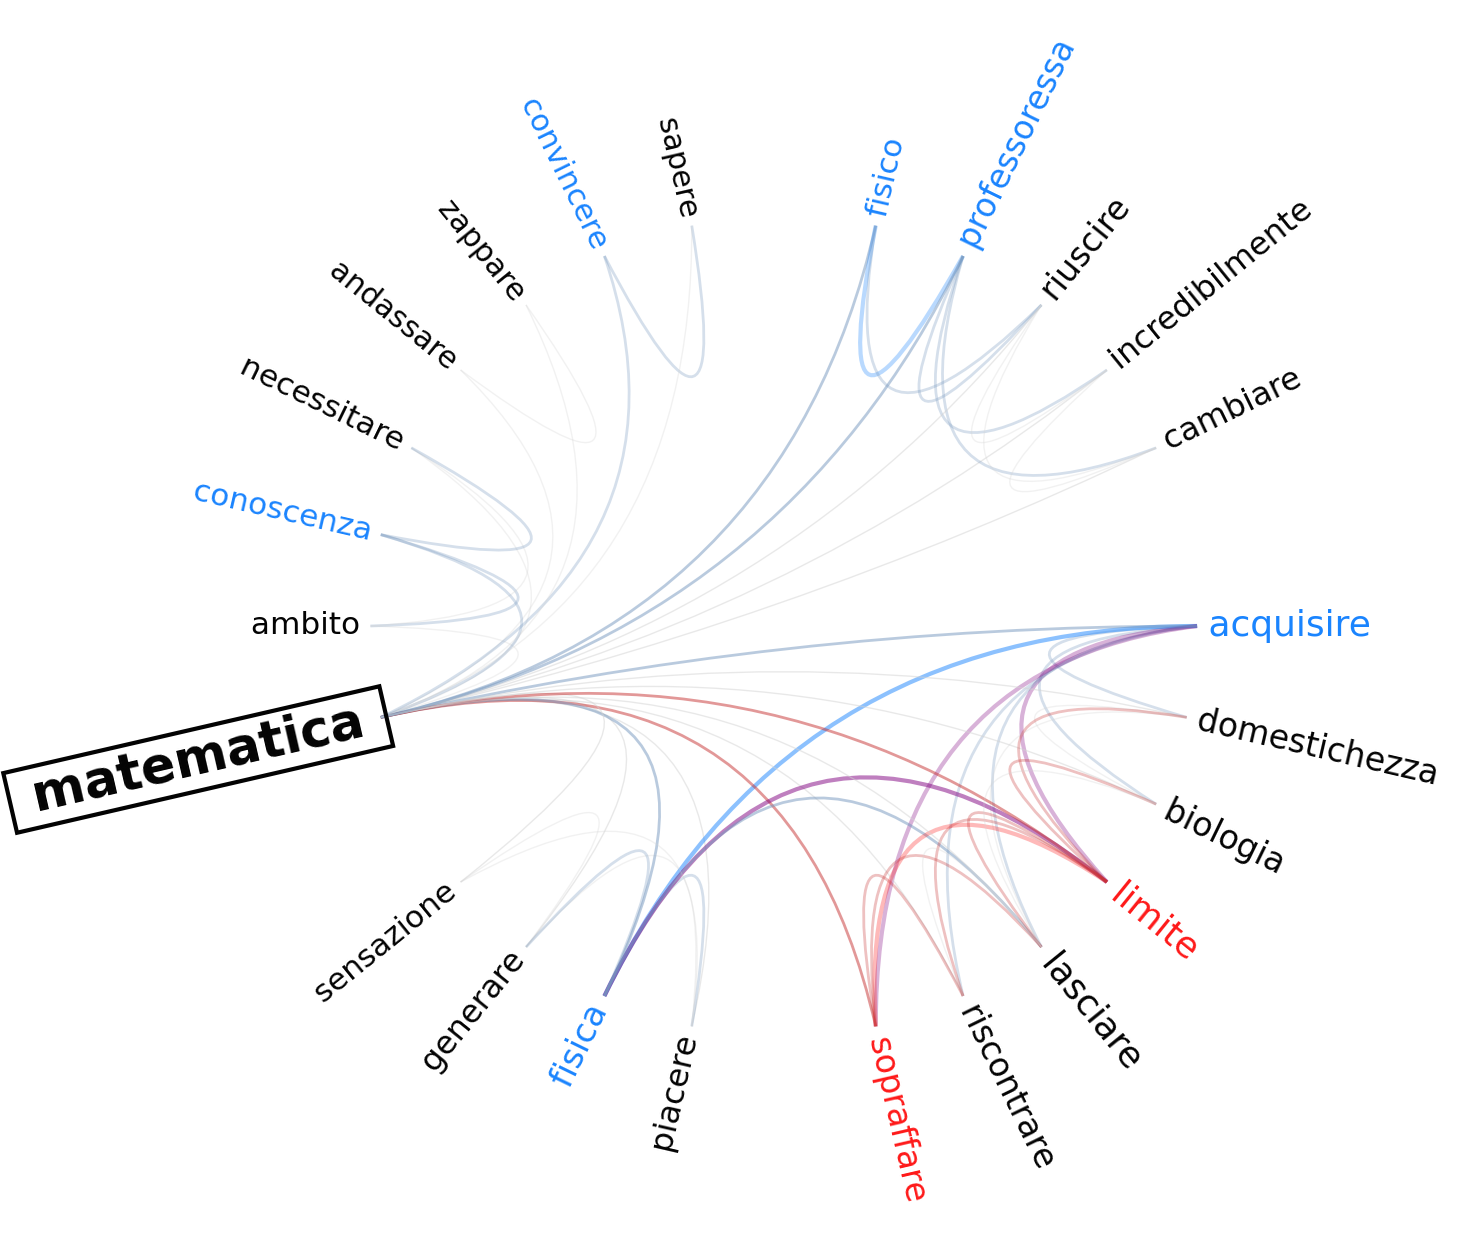

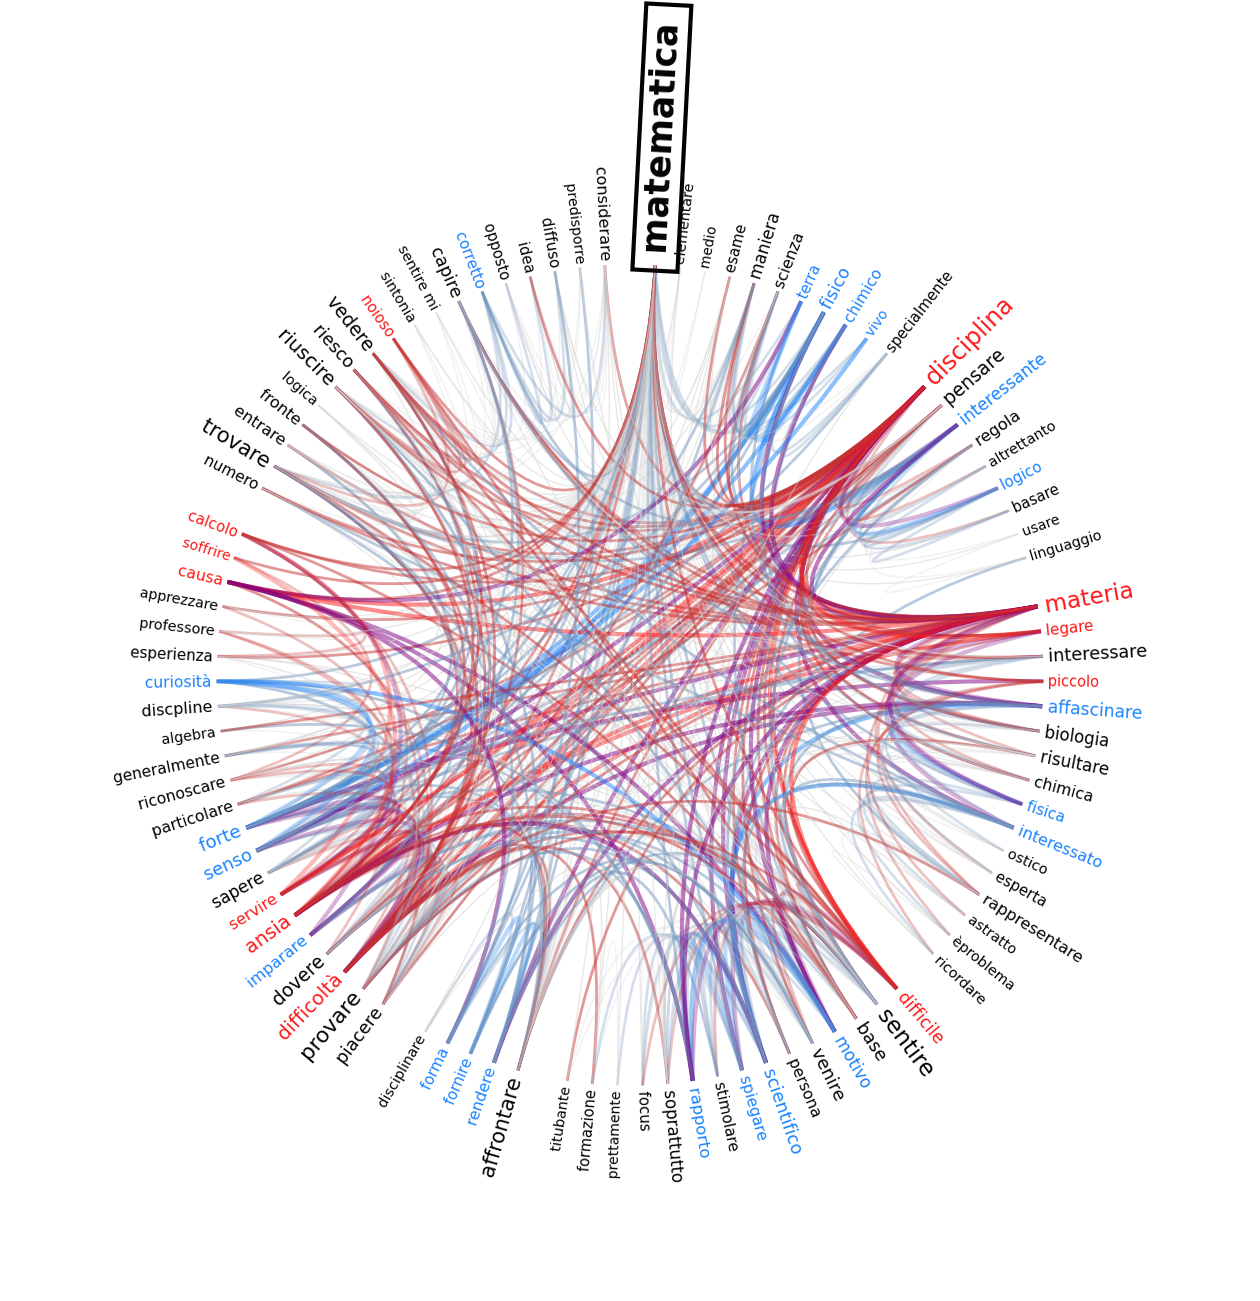

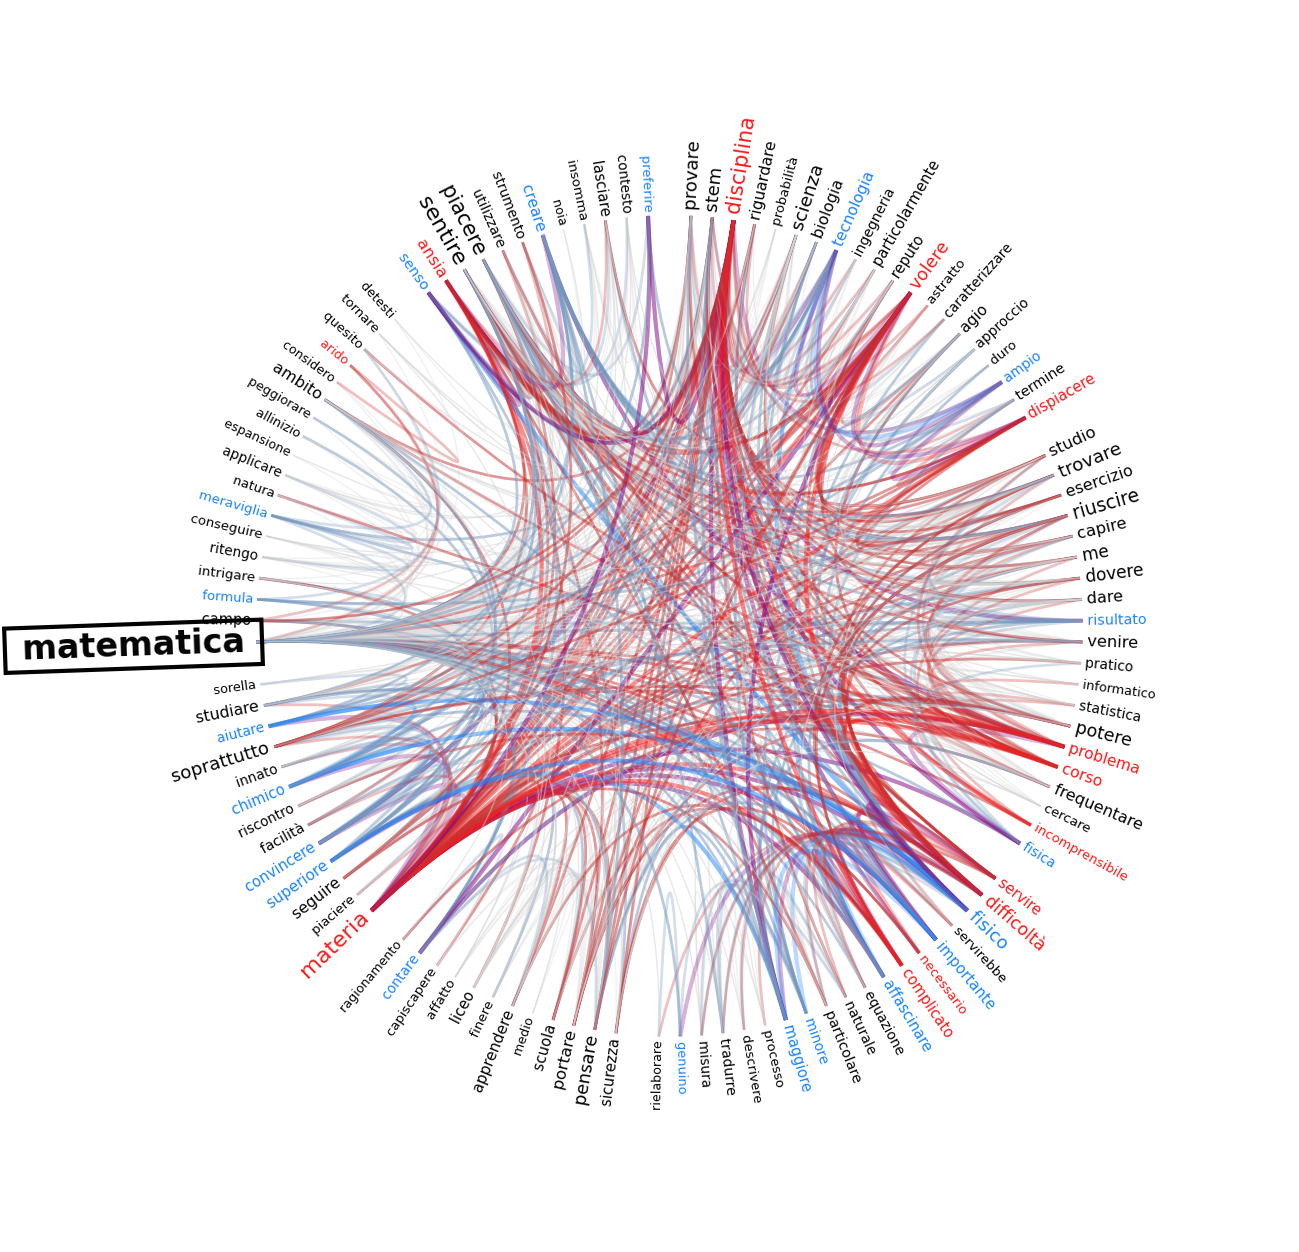

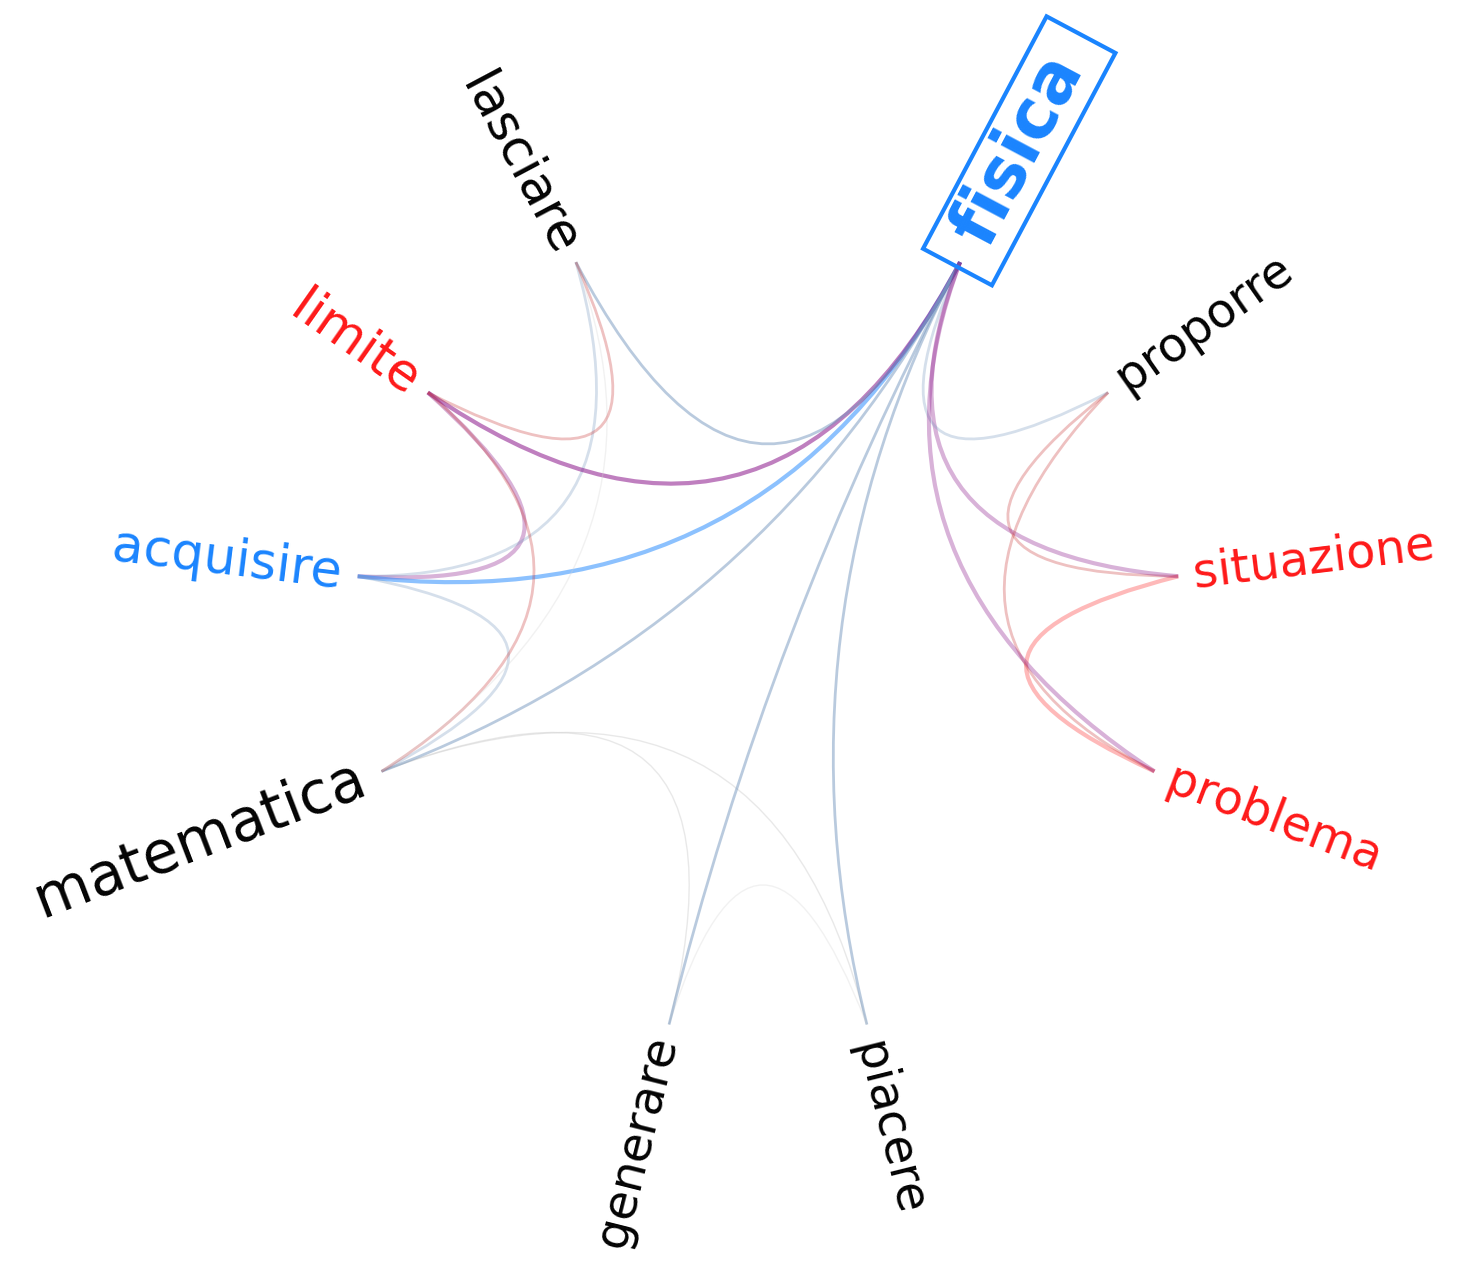

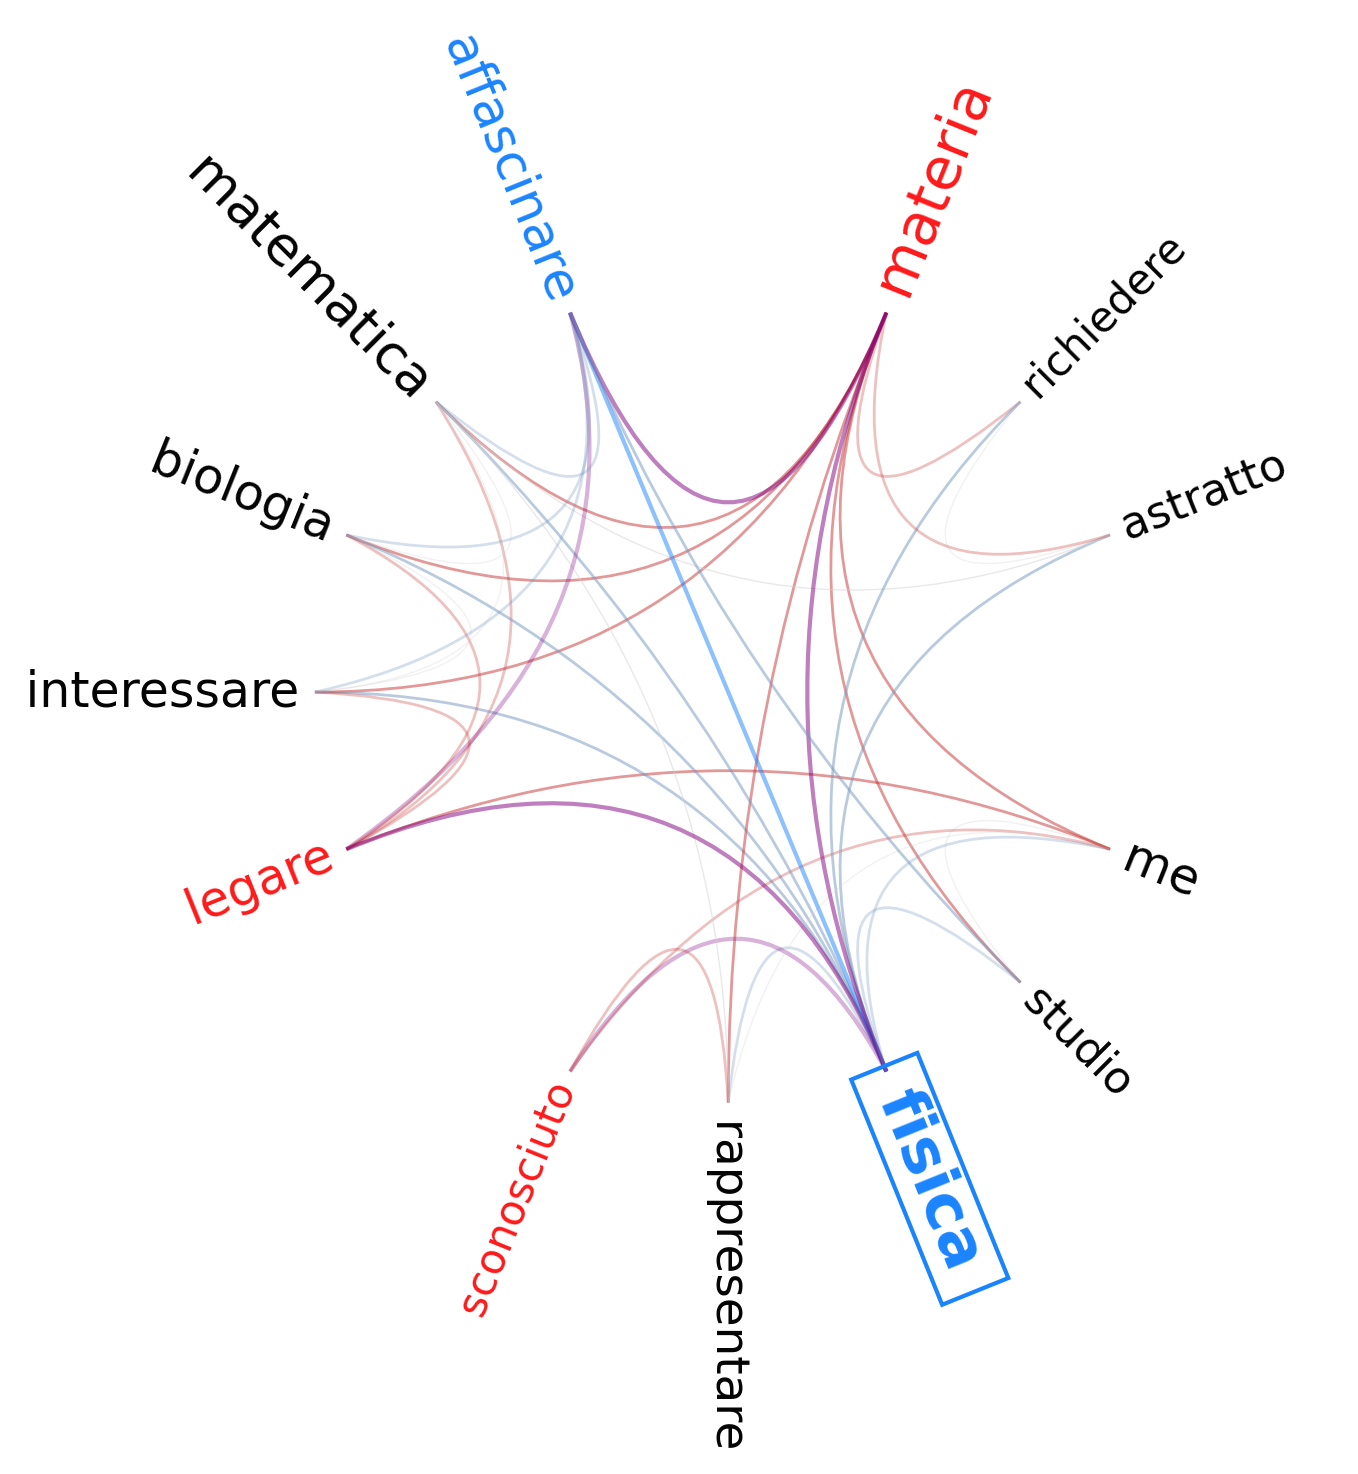

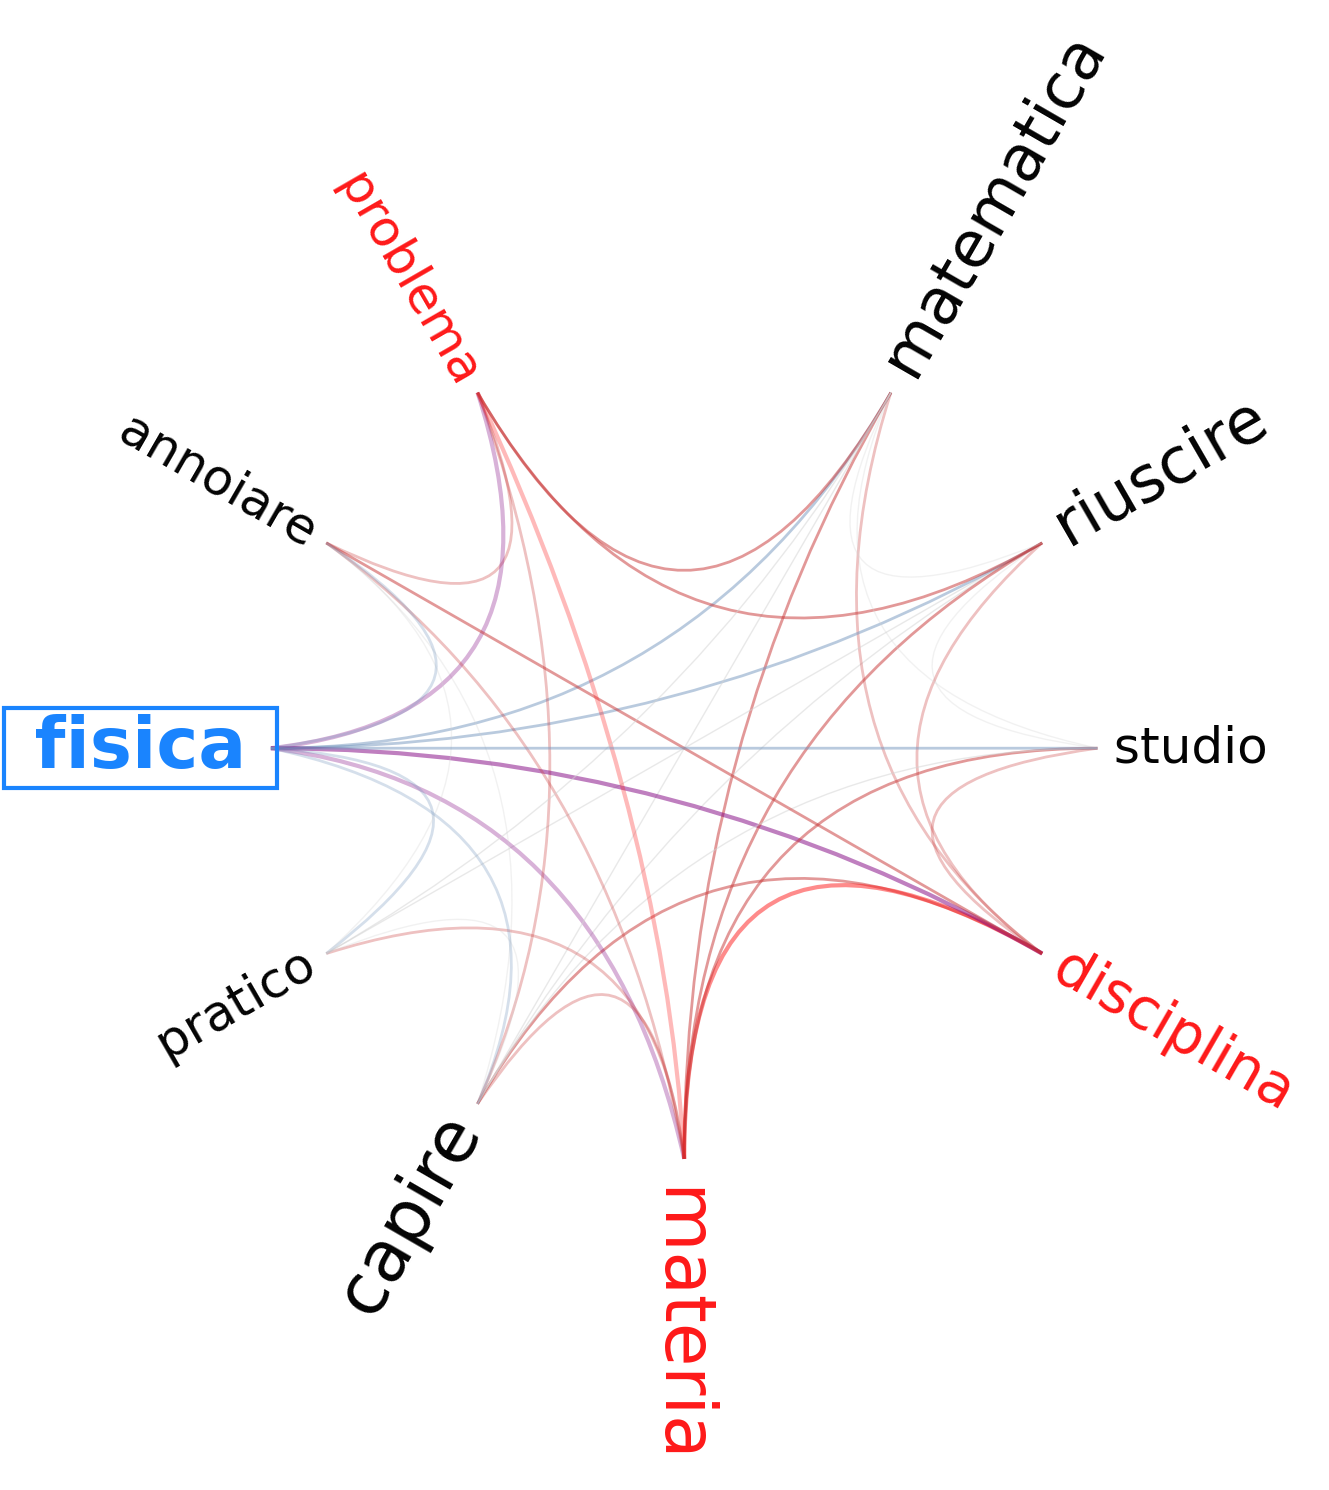

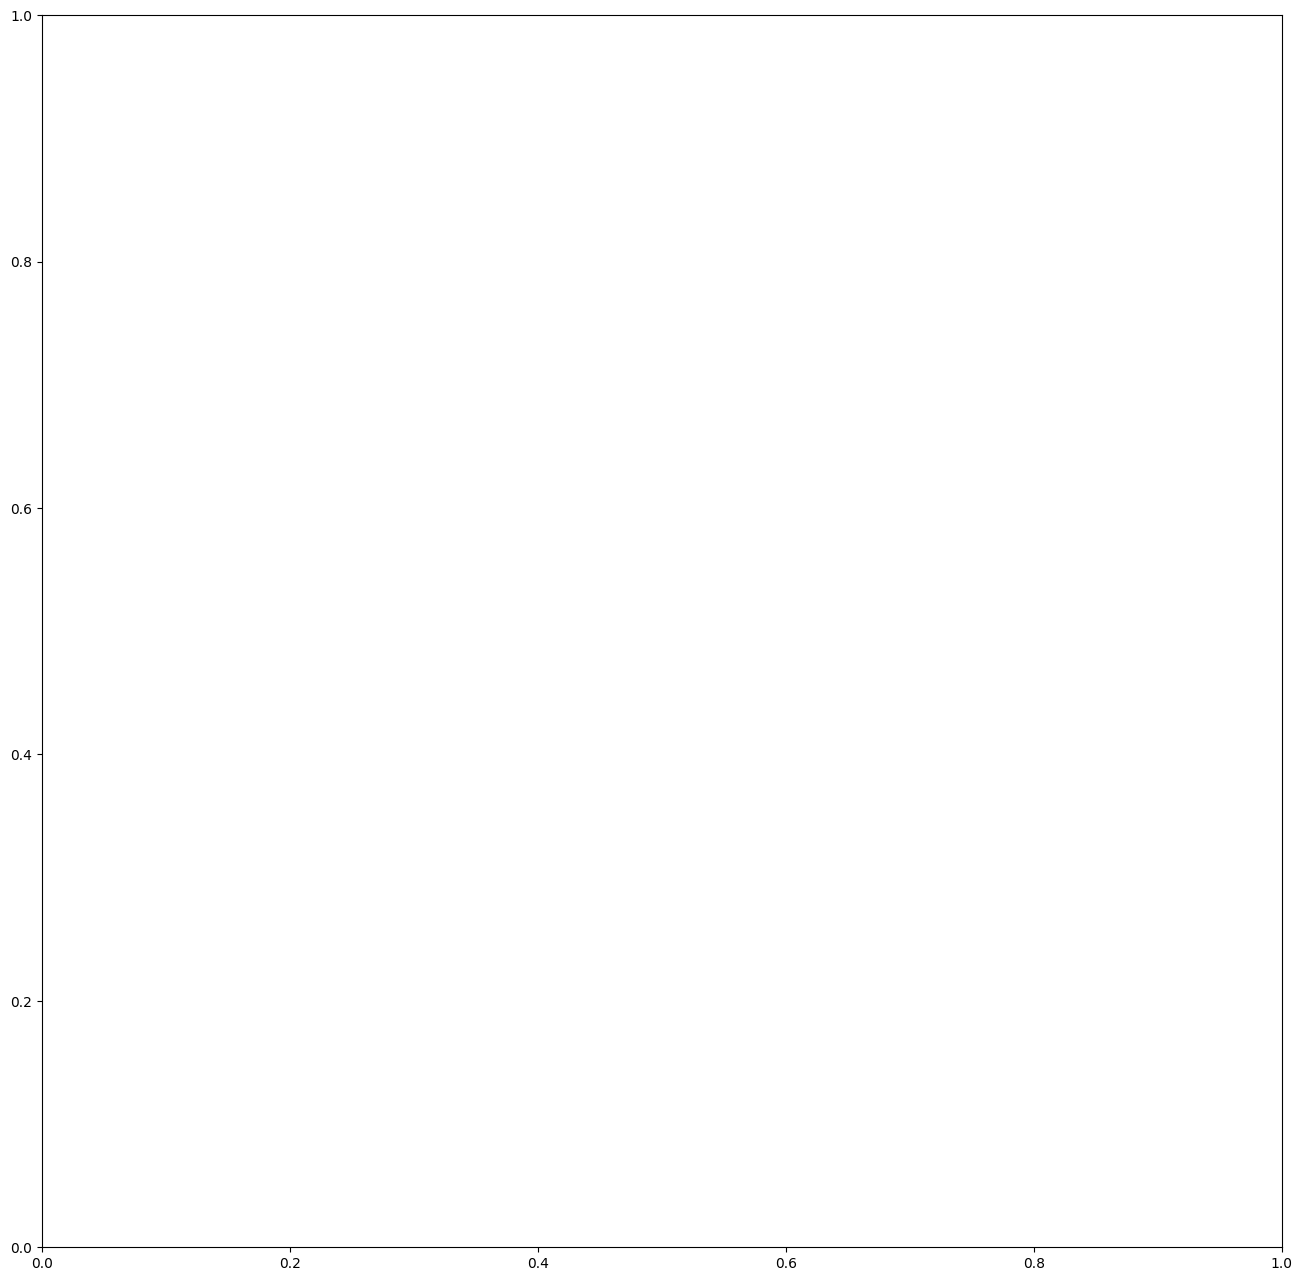

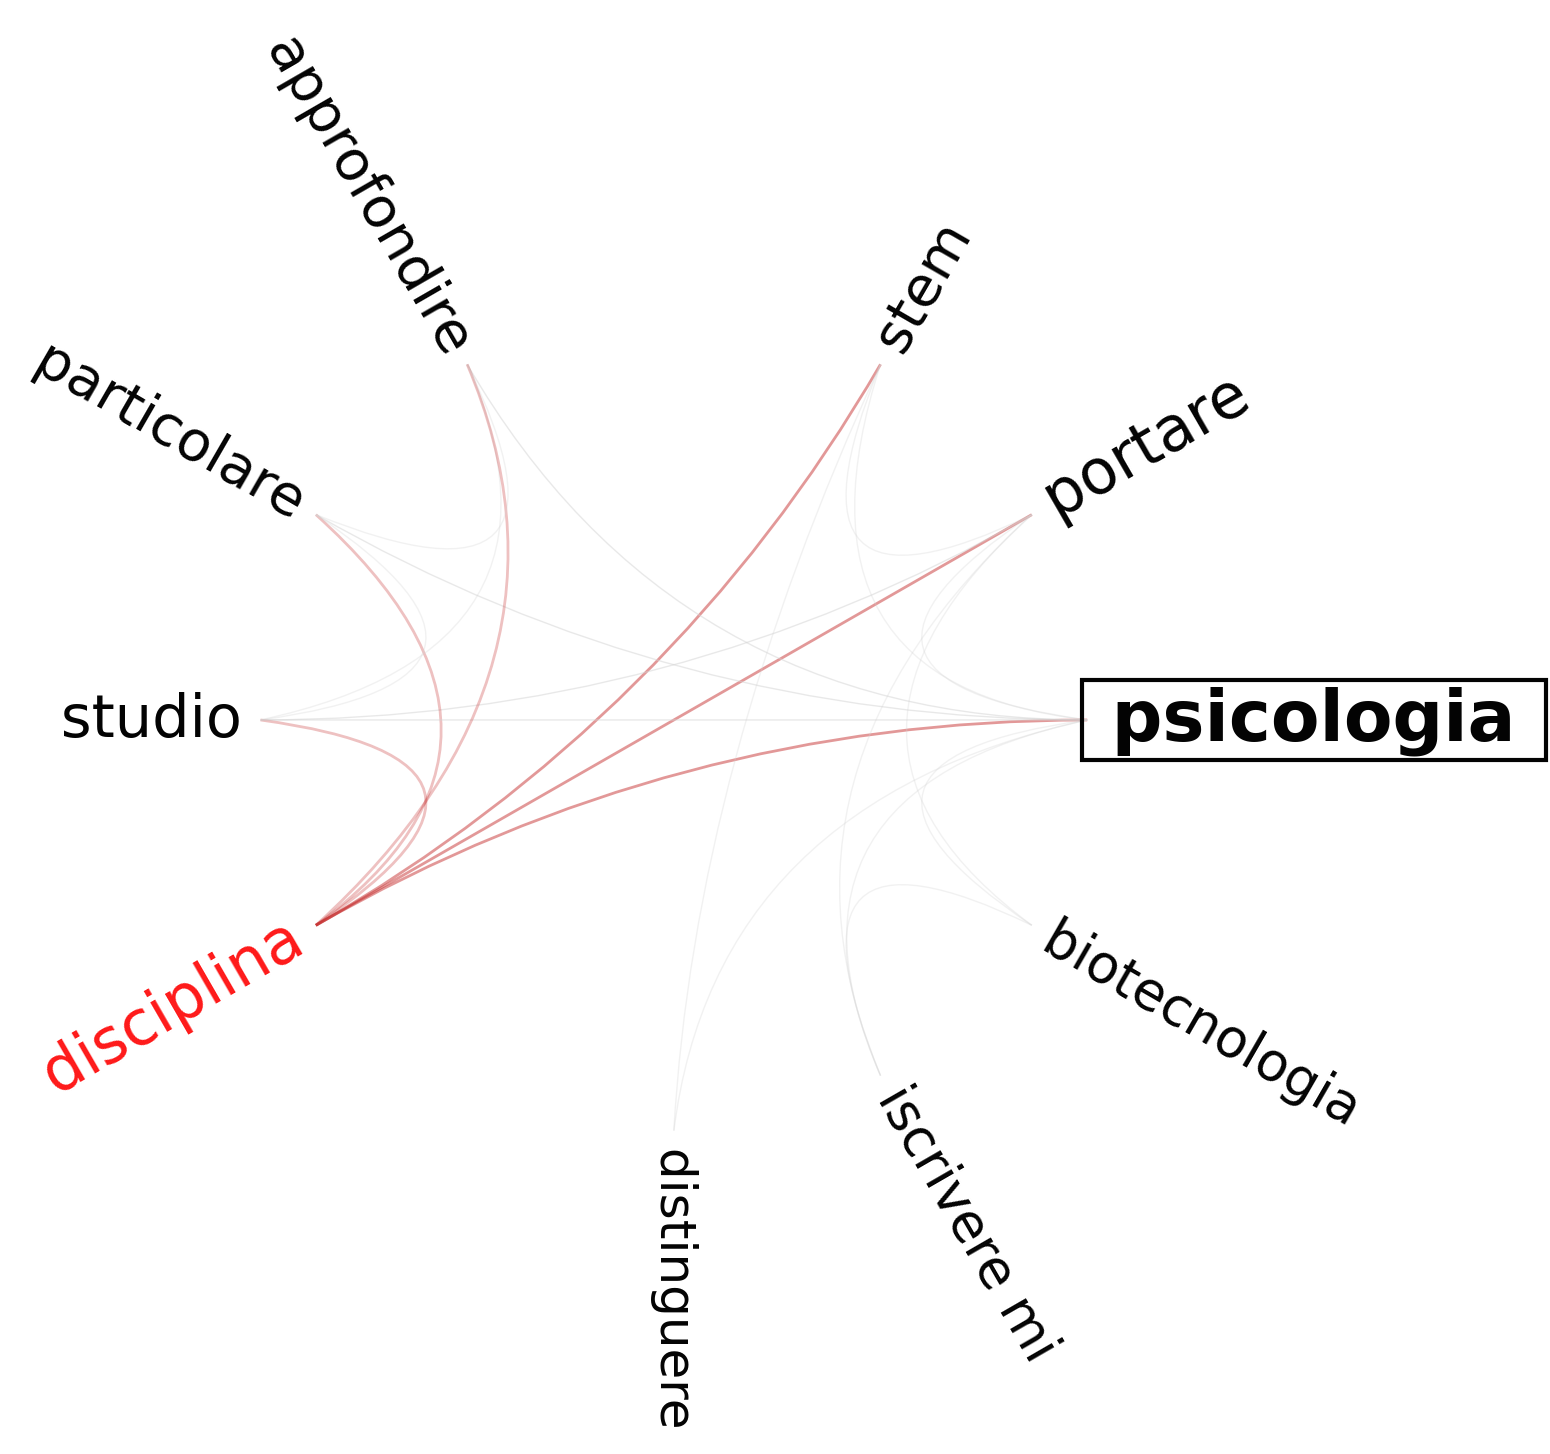

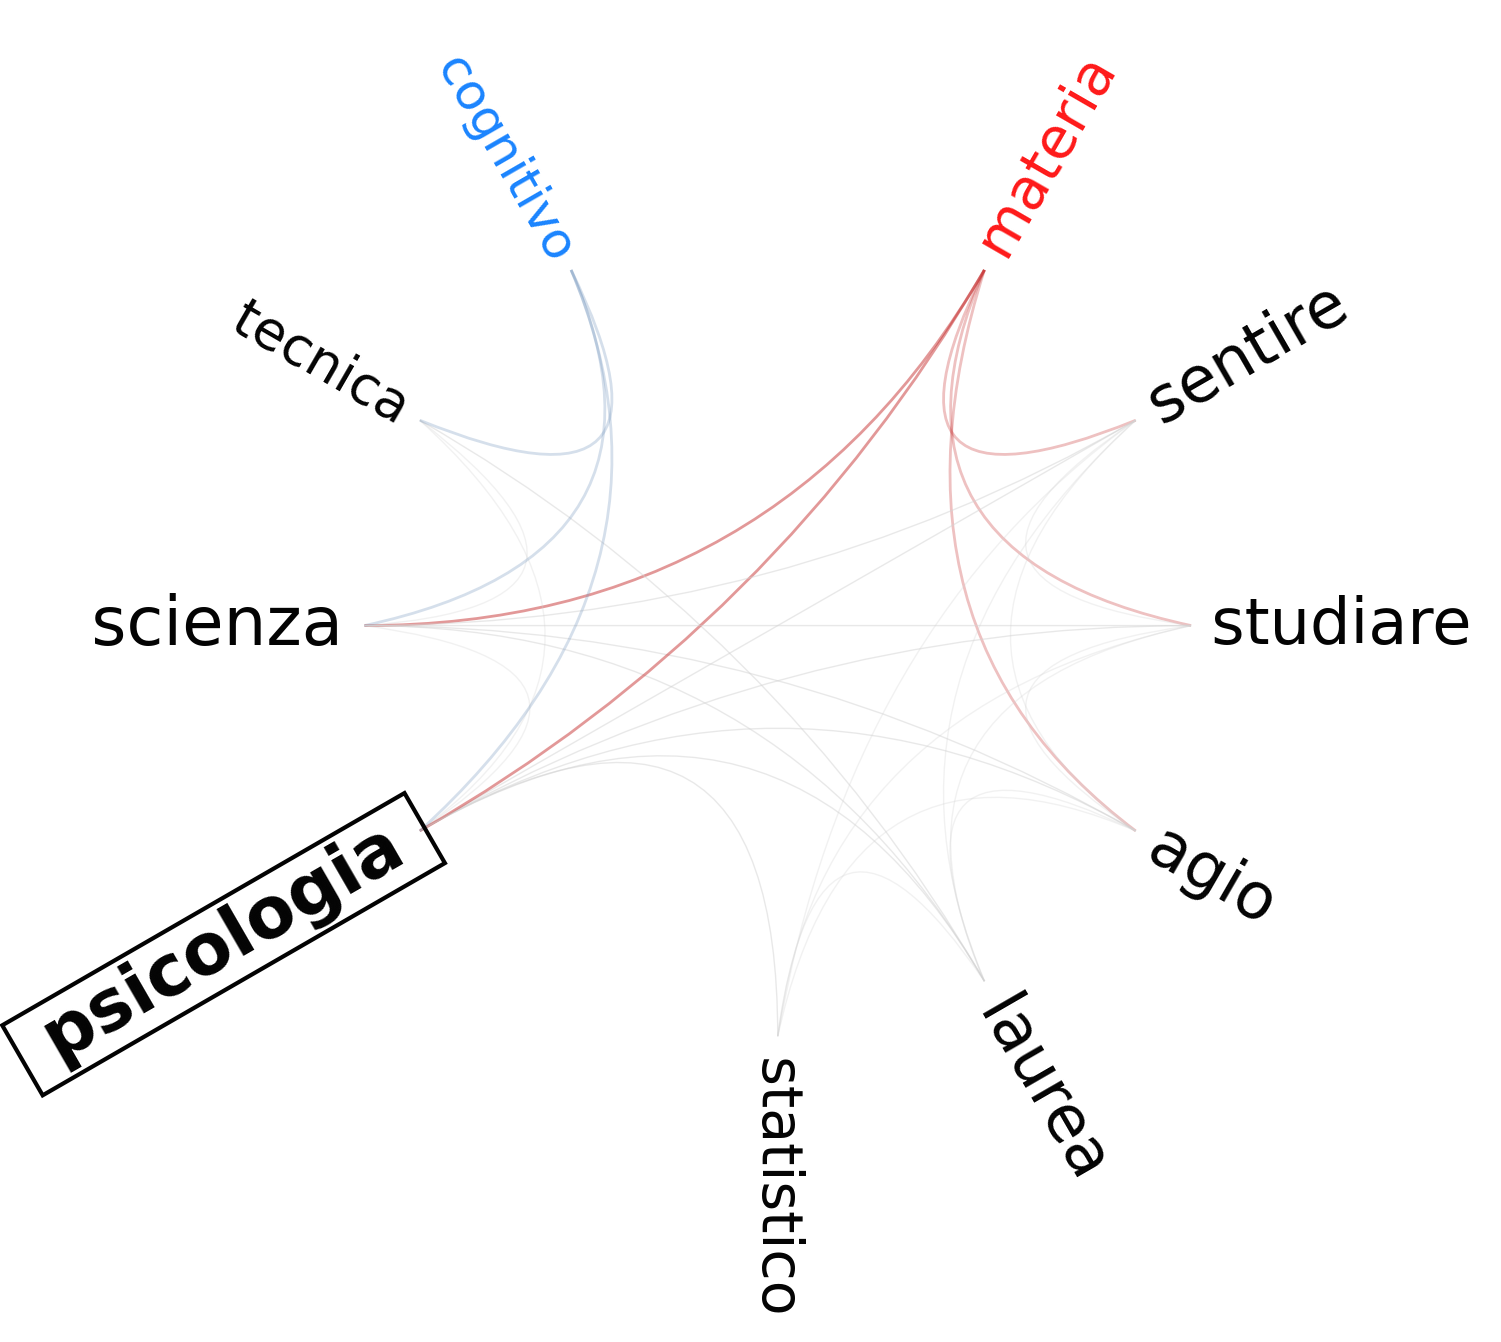

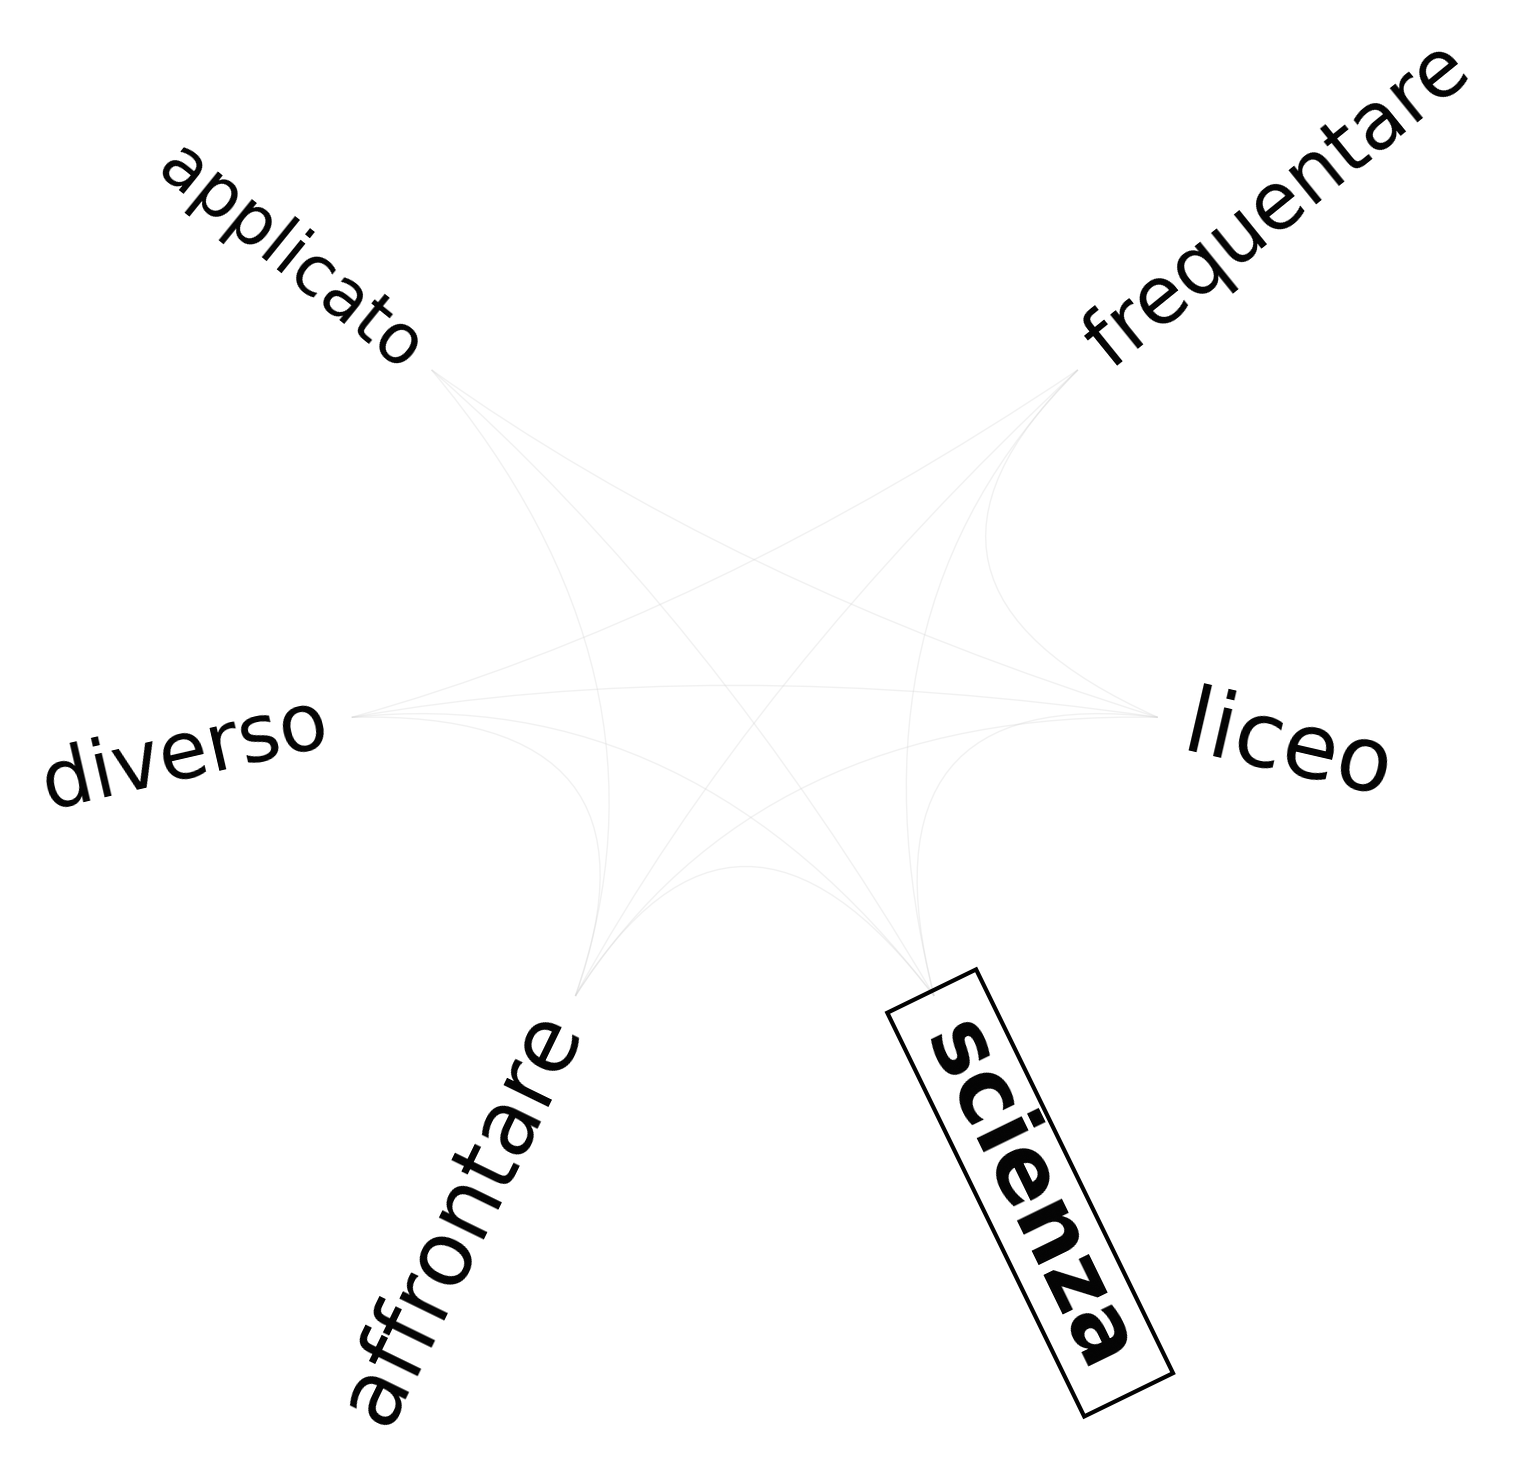

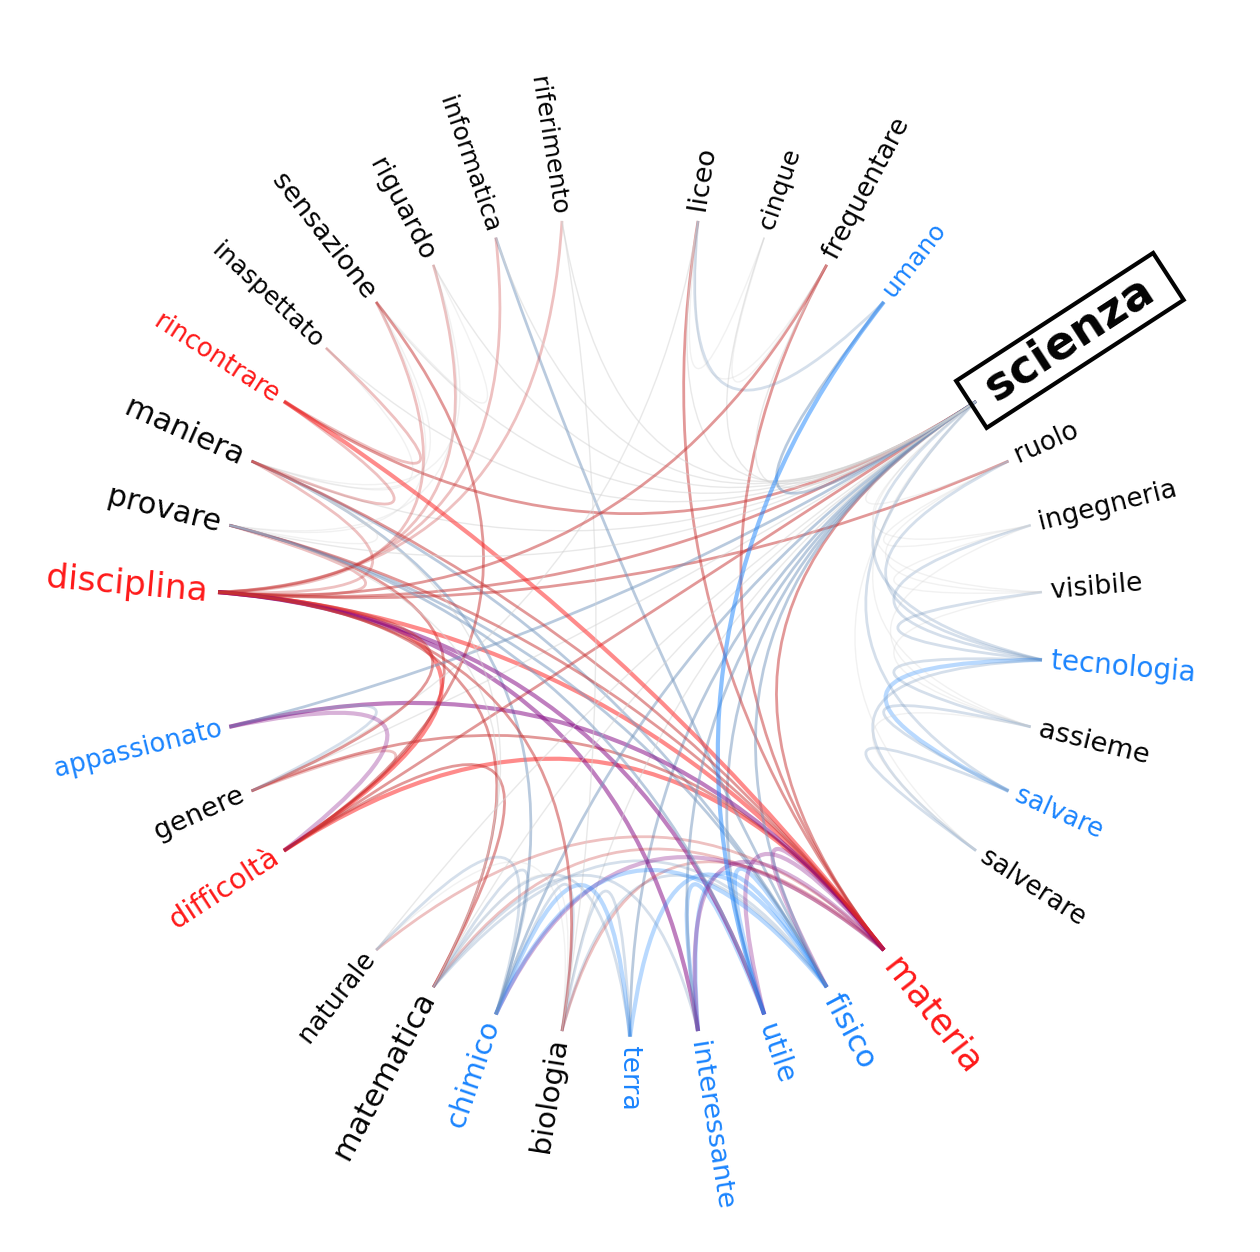

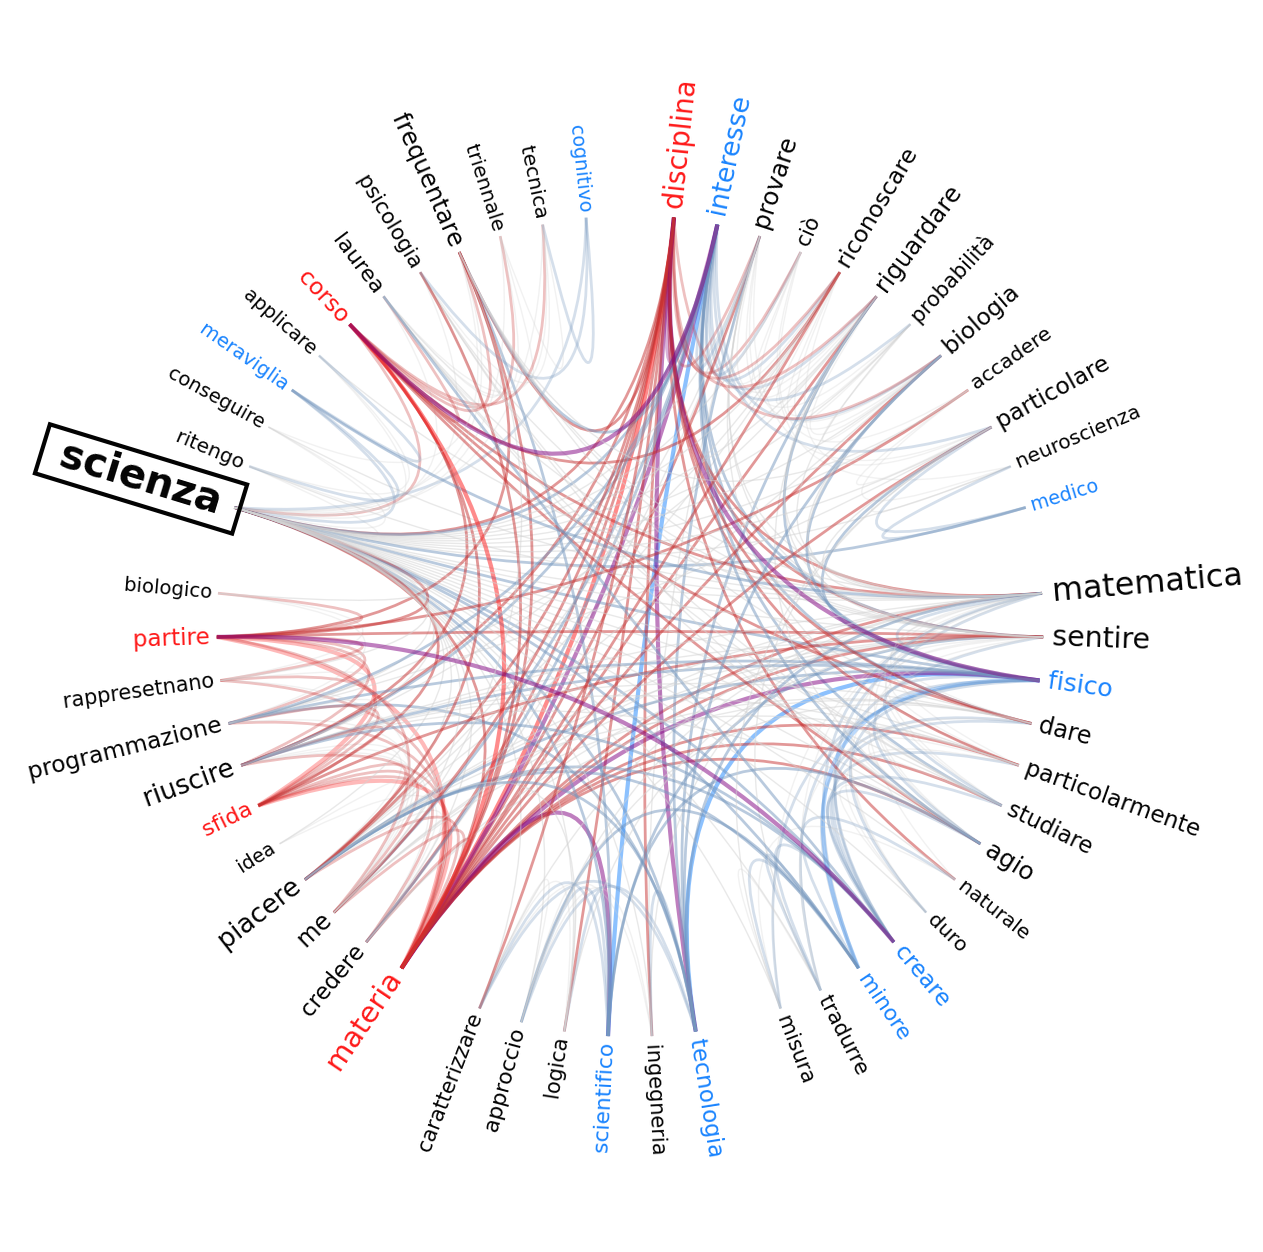

In [ ]:
all_fmnts = {}
titles = []

# building different forma mentis network for each keyword and the the data of each academic year (total of 12 figures)
for keyword in keywords:
    for year, text_year in zip(years, all_texts):
        # creates a list for all the titles of the different figures
        title = f"{keyword}_{year}_year"
        titles.append(title)

        try: 
            # builds the forma mentis network assigning them a title and inserting them into a dict
            fmnt = emos.formamentis_network(text_year, target_word=keyword)
            all_fmnts[title] = fmnt 
            # draws the fmnt and saves it in a folder inserting in the file name the number of vertices of the fmnt
            emos.draw_formamentis(
                fmnt,
                highlight=keyword,
                save_path=f'{path}/out/analysis/tfmn/psychology_BA_2024/{title}_n_{len(fmnt.vertices)}'
            )

        # if the data is not sufficient a ValueError will rise, so we skip that fmnt and move to the next one
        except ValueError as e:
            if "min() iterable argument is empty" in str(e):
                print(f"⚠️ Skipping {title}: not enough data to build the network.")
            else:
                raise

## Emotional flowers building

In [ ]:
# takes into account all the fmnt previously built, builds the emotional flowers, calculating the zeta scores
for fmnt, title in zip(all_fmnts.keys(), titles):
    zeta_scores = emos.zscores(all_fmnts[fmnt])
    emos.draw_plutchik(zeta_scores, reject_range=(-1.96, 1.96))

    # saves the figures using matplotlib and closes them
    plt.savefig(f"{path}/out/analysis/emotional_flowers/psychology_BA_2024/{title}")
    plt.close()

## Most common words

In [ ]:
# loading the set of stop words present in Italian
stop_words = set(stopwords.words('italian'))

# function to extract the most common words
def extract_top_frequent_words(text, top_n=10):
    
    # extracting all different words
    words = re.findall(r'\b\w+\b', text.lower())

    # checking if they're not stop words
    filtered_words = [word for word in words if word not in stop_words]

    # counting the frequency of the words
    word_counts = Counter(filtered_words)

    # returning the most common ones
    return word_counts.most_common(top_n)

# calling the function for the data of each year
top_words_1 = extract_top_frequent_words(testi_primo_anno, top_n=20)
top_words_2 = extract_top_frequent_words(testi_secondo_anno, top_n=20)
top_words_3 = extract_top_frequent_words(testi_terzo_anno, top_n=20)

# printing them
print(f"{top_words_1} \n{top_words_2} \n{top_words_3}")

Then we can build forma mentis networs and emotional flowers for the most common words of each year

# Data 2025

In [11]:
data_2025 = pd.read_csv(f"{path}/out/formatting/all_students_2025/free_text.csv")

def extract_text(prefix):
    data = data_2025[data_2025['participant_id'].str.startswith(prefix)]
    texts_str = data['text'].astype(str)
    texts = ".".join(texts_str)
    return texts

liceo_texts = extract_text('liceo')
liceo_sci_texts = extract_text('liceo_sci')
liceo_lin_texts = extract_text('liceo_lin')

all_texts = [liceo_texts, liceo_sci_texts, liceo_lin_texts]

keywords_liceo = ['matematica', 'ansia', 'scientifico', 'materia']
names = ['liceo', 'liceo_sci', 'liceo_lin']

len(liceo_texts)

34081

In [12]:
for text in all_texts:
    print(len(text))

34081
23478
10602


In [13]:
data_stem = data_2025[data_2025['participant_id'].isin(['fisica_stem_001', 'fisica_stem_002'])]
texts_str = data_stem['text'].astype(str)
texts_stem = ".".join(texts_str)
texts_stem

"quando affronto le materie scientifiche ho generalmente due reazioni. una, che se si verifica e' la prima, che cerca di evitarle e di non darle attenzione perché ha paura della seconda, che consiste nel fatto che mi perdo completamente nel loro studio, ed è come se mi alienassi dalla realtà e questa cosa quando accade è davvero molto bella ma anche molto pericolosa, perché perdo il controllo e mi rendo conto che questo non mi fa bene come essere umano perché mi alieno dal mondo, taglio i rapporti con gli altri e mi metto a vivere in un mondo tutto mio che è distante da quello reale, e questo non fa bene ai rapporti sociali perché, alla fine, sono sempre da sola. un'altra cosa che è collegata è il fatto che quando vedo delle scritte matematiche mi sento felice perché è come se fossero scritte in un'altra lingua, che adesso dopo i corsi all'università capisco bene, e poi mi faccio molto affascinare quando una qualsiasi altra persona mi parla di scienza, mi brillano gli occhi ed è una co

In [ ]:
fmnts_stem = []
for keyword in keywords_liceo:
    try:
        fmnt = emos.formamentis_network(texts_stem, target_word=keyword)
        fmnts_stem.append(fmnt)
        emos.draw_formamentis(fmnt, highlight=keyword)

    except ValueError as e:
        if "min() arg is an empty sequence" in str(e):
            print(f"⚠️ Skipping {keyword}: not enough data to build the network.")

In [ ]:
path_names = []

for keyword in keywords_liceo:
    for name in names:
        path_names.append(f"{keyword}_{name}")

path_names

In [ ]:
fmnts_liceo = []

for text, name in zip(all_texts, names): 
    for keyword in keywords_liceo:
        try:
            fmnt = emos.formamentis_network(text, target_word=keyword)
            fmnts_liceo.append(fmnt)
            emos.draw_formamentis(fmnt, highlight=keyword, save_path=f"fmnts_liceo_2025/{name}_{keyword}_n_{len(fmnt.vertices)}")
            
        except ValueError as e:
            if "min() arg is an empty sequence" in str(e):
                print(f"⚠️ Skipping {keyword}: not enough data to build the network.")

In [ ]:
for fmnt, path_name in zip(fmnts_liceo, path_names):
    print(path_name)
    zeta_scores = emos.zscores(fmnt)
    emos.draw_plutchik(zeta_scores, reject_range=(-1.96, 1.96))

    # # saves the figures using matplotlib and closes them
    plt.savefig(f"emotional_flowers_2025/{path_name}")
    plt.close()

# SociaLLMisinformation

In [4]:
path_social = '/Users/emma/projects/cognoscolab/sociallmisinformation'

In [5]:
climate_change_llama = pd.read_csv(f'{path_social}/data/climate/Llama-3-8B.csv')
gwarming_llama = pd.read_csv(f'{path_social}/data/gwarming/Llama-3.1-70B.csv')
health_llama = pd.read_csv(f'{path_social}/data/misinformation_health/Llama-3.1-70B.csv')

In [9]:
sample_climate = climate_change_llama['text'].sample(n=100, random_state=42)

# subset = []
# for text in sample_climate:
#     if "human activities" in text:
#         subset.append(text)

texts_climate = ". ".join(sample_climate)
len(texts_climate)

361226

In [14]:
fmnt_climate = emos.formamentis_network(texts_climate, target_word='emission')
# emos.draw_formamentis(fmnt_climate)

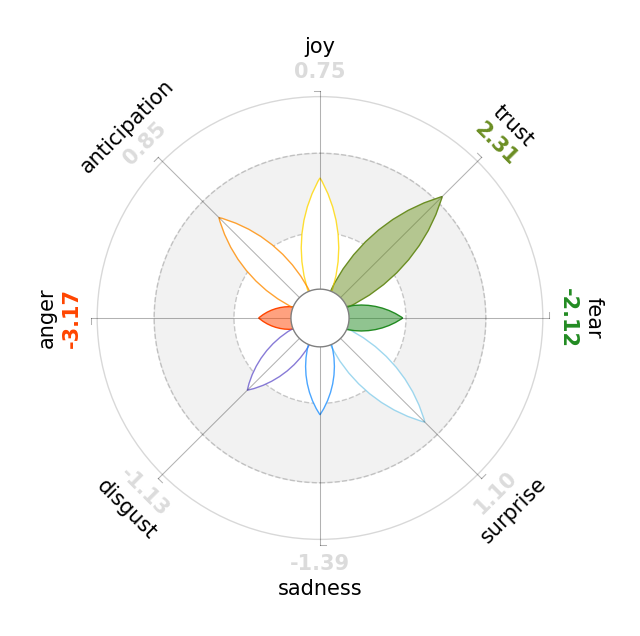

In [15]:
zeta_scores = emos.zscores(fmnt_climate)
emos.draw_plutchik(zeta_scores, reject_range=(-1.96, 1.96))

In [28]:
health_vertices = fmnt_health.vertices
misinformation_vertices = fmnt_misinformation.vertices

difference_list = list(set(health_vertices).intersection(set(misinformation_vertices)))
print(difference_list)
len(difference_list)

['theory', 'topic', 'misinformation', 'realm', 'concern', 'voice', 'perpetuate', 'panic', 'conspiracy', 'health', 'phenomena', 'wellness', 'surround', 'combat', 'environment', 'create', 'issue', 'relate']


18